# Reusing the generated solver (appendix of the paper)

This notebook draws the figure of the appendix "Reusing the generated solver" and prints the rows of its two tables. It reads the result files of two scripts in `scripts/evaluation/`.

| Content | Script | Files under `data/analysis/` |
|---|---|---|
| 20-step errors at every refresh interval | `flux_refresh.py` | `flux_refresh/cubic_1d.hdf5`, `flux_refresh/cubic_1d_shock.hdf5` |
| Time of one rollout step | `compute_cost.py` | `compute_cost/cubic_1d.hdf5` (refresh interval 8), `compute_cost/cubic_1d_refresh{2,4,20}.hdf5` |

The errors on 2D cubic are the one exception. They are typed in from the appendix of the submission, because the code that computed them is not on this branch.

A missing file is printed and left out, so the notebook runs while results are still coming in.

In [1]:
import json
from pathlib import Path

import colorcet as cc
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D


analysis_dir = Path("../../data/analysis")
figure_dir = Path("../../figures")

HFLUXNO = "HyperFluxFNOLocal"
DPOT = "DPOT"
COLORS = {HFLUXNO: cc.cm.glasbey_bw(41), DPOT: cc.cm.glasbey_bw(85)}
ERROR_FIELDS = ("l2_rollout", "l_inf_rollout", "l2_final", "l_inf_final")
# Result files of flux_refresh.py -> names of the paper.
ERROR_FILES = {"cubic_1d": "1D cubic", "cubic_1d_shock": "1D cubic, shock IC"}
# Result files of compute_cost.py. The first is the run behind the cost table of the
# paper, and the rollout without reuse and the time of DPOT are taken from it.
COST_FILES = (
    "cubic_1d",
    "cubic_1d_refresh2",
    "cubic_1d_refresh4",
    "cubic_1d_refresh20",
)

# 20-step relative errors of HFluxNO on 2D cubic, (mean, std) over three training runs,
# from the appendix "Reusing the generated solver" of the submission. They were
# computed with code that is not on this branch, so they are typed in here. Every other
# number of this notebook is read from a result file.
CUBIC_2D = {
    "2D cubic": {
        "l2_rollout": {
            1: (0.0131, 0.00065),
            2: (0.0125, 0.00056),
            4: (0.0112, 0.00040),
            8: (0.00999, 0.00029),
        },
        "l_inf_rollout": {
            1: (0.0638, 0.0034),
            2: (0.0603, 0.0029),
            4: (0.0545, 0.0021),
            8: (0.0487, 0.0016),
        },
    },
    "2D cubic, shock IC": {
        "l2_rollout": {
            1: (0.176, 0.024),
            2: (0.169, 0.024),
            4: (0.159, 0.022),
            8: (0.144, 0.020),
        },
        "l_inf_rollout": {
            1: (0.565, 0.075),
            2: (0.553, 0.077),
            4: (0.527, 0.073),
            8: (0.486, 0.067),
        },
    },
}

# The rc of Fig. 4 (long_term_rollouts.ipynb), so the fonts match at the page width.
PAPER_RC = {
    "font.size": 7,
    "axes.titlesize": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "axes.linewidth": 0.6,
    "pdf.fonttype": 42,
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
}

## Errors

Each seed is averaged over its segments, and a cell shows the mean and the standard deviation over the three seeds. On the shock-dominated set, a constant initial condition can make the relative error non-finite; the fraction of such segments is printed.

In [2]:
def mean_over_finite(values: np.ndarray, axis: tuple[int, ...]) -> np.ndarray:
    """Average over `axis`, leaving out the entries that are not finite."""
    is_finite = np.isfinite(values)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(is_finite, values, 0.0).sum(axis=axis) / is_finite.sum(
            axis=axis
        )


def load_refresh_errors(name: str) -> dict[str, dict[int, tuple[float, float]]] | None:
    """Read one file of flux_refresh.py.

    Returns, per error, the mean and the standard deviation over the seeds at every
    refresh interval. Each seed is first averaged over its finite segments. A missing
    file is printed and gives `None`.
    """
    path = analysis_dir / "flux_refresh" / f"{name}.hdf5"
    if not path.exists():
        print(f"Missing {path}")
        return None
    with h5py.File(path, "r") as f:
        intervals = [int(r) for r in f.attrs["refresh_every"]]
        errors = {}
        for field in ERROR_FIELDS:
            segments = f[f"models/{HFLUXNO}/{field}"][()]
            left_out = 1.0 - np.isfinite(segments).mean()
            if left_out > 0.0:
                print(f"{name}, {field}: {left_out:.2%} of the segments are not finite")
            per_seed = mean_over_finite(segments, axis=(1, 2))
            errors[field] = {
                r: (float(per_seed[:, i].mean()), float(per_seed[:, i].std()))
                for i, r in enumerate(intervals)
            }
    return errors


errors = dict(CUBIC_2D)
for name, label in ERROR_FILES.items():
    loaded = load_refresh_errors(name)
    if loaded is not None:
        errors[label] = loaded
# The order of the paper: 1D before 2D, in distribution before shock.
ERROR_SETS = [s for s in (*ERROR_FILES.values(), *CUBIC_2D) if s in errors]

for label in ERROR_SETS:
    print(label)
    display(
        pd.DataFrame(
            {
                field: {r: f"{m:.3e} ± {s:.1e}" for r, (m, s) in by_r.items()}
                for field, by_r in errors[label].items()
            }
        ).rename_axis("refresh every")
    )

1D cubic


,l2_rollout,l_inf_rollout,l2_final,l_inf_final
refresh every,,,,
1,5.221e-02 ± 2.1e-03,3.685e-01 ± 1.6e-02,9.386e-02 ± 3.9e-03,3.839e-01 ± 1.7e-02
2,4.977e-02 ± 2.0e-03,3.514e-01 ± 1.5e-02,8.926e-02 ± 3.6e-03,3.659e-01 ± 1.6e-02
4,4.611e-02 ± 1.7e-03,3.243e-01 ± 1.3e-02,8.207e-02 ± 3.1e-03,3.371e-01 ± 1.4e-02
8,4.162e-02 ± 1.3e-03,2.894e-01 ± 1.0e-02,7.299e-02 ± 2.5e-03,2.997e-01 ± 1.1e-02
20,3.758e-02 ± 8.0e-04,2.449e-01 ± 5.3e-03,6.199e-02 ± 1.2e-03,2.529e-01 ± 5.6e-03


1D cubic, shock IC


,l2_rollout,l_inf_rollout,l2_final,l_inf_final
refresh every,,,,
1,6.700e-02 ± 1.7e-03,4.354e-01 ± 9.0e-03,1.157e-01 ± 2.9e-03,4.402e-01 ± 9.1e-03
2,6.465e-02 ± 1.6e-03,4.202e-01 ± 8.8e-03,1.115e-01 ± 2.8e-03,4.247e-01 ± 8.8e-03
4,6.088e-02 ± 1.6e-03,3.944e-01 ± 8.4e-03,1.044e-01 ± 2.7e-03,3.983e-01 ± 8.5e-03
8,5.555e-02 ± 1.5e-03,3.573e-01 ± 7.8e-03,9.465e-02 ± 2.5e-03,3.606e-01 ± 7.8e-03
20,4.912e-02 ± 1.5e-03,2.947e-01 ± 7.0e-03,7.835e-02 ± 2.4e-03,2.954e-01 ± 7.0e-03


2D cubic


,l2_rollout,l_inf_rollout
refresh every,,
1,1.310e-02 ± 6.5e-04,6.380e-02 ± 3.4e-03
2,1.250e-02 ± 5.6e-04,6.030e-02 ± 2.9e-03
4,1.120e-02 ± 4.0e-04,5.450e-02 ± 2.1e-03
8,9.990e-03 ± 2.9e-04,4.870e-02 ± 1.6e-03


2D cubic, shock IC


,l2_rollout,l_inf_rollout
refresh every,,
1,1.760e-01 ± 2.4e-02,5.650e-01 ± 7.5e-02
2,1.690e-01 ± 2.4e-02,5.530e-01 ± 7.7e-02
4,1.590e-01 ± 2.2e-02,5.270e-01 ± 7.3e-02
8,1.440e-01 ± 2.0e-02,4.860e-01 ± 6.7e-02


## Time of one rollout step

The time is the median over the timed calls of a 20-step rollout, divided by the batch size and by the 20 steps. The rollout without reuse (refresh interval 1) and the time of DPOT come from `cubic_1d.hdf5`, the run behind the cost table of the paper.

In [3]:
def step_time_ms(group: h5py.Group, rollout_steps: int) -> float:
    """The median time of one rollout step in ms, per trajectory of the batch."""
    batch = int(group.name.rsplit("batch", 1)[1])
    return 1e3 * float(np.median(group["seconds"][()])) / batch / rollout_steps


def load_step_times() -> tuple[dict[str, dict[int, float]], dict[str, float], int]:
    """Read the files of compute_cost.py.

    Returns the time per step of HFluxNO at every refresh interval and that of DPOT,
    each for the batched rollout and for a single trajectory, and the batch size.
    """
    hfluxno: dict[str, dict[int, float]] = {"batched": {}, "single": {}}
    dpot: dict[str, float] = {}
    eval_batch = 0
    for name in COST_FILES:
        path = analysis_dir / "compute_cost" / f"{name}.hdf5"
        if not path.exists():
            print(f"Missing {path}")
            continue
        with h5py.File(path, "r") as f:
            config = json.loads(f.attrs["config"])
            steps, interval = config["rollout_steps"], config["refresh_every"]
            eval_batch = config["eval_batch"]
            batches = {"batched": eval_batch, "single": 1}
            model = f[f"models/{HFLUXNO}"]
            for mode, batch in batches.items():
                hfluxno[mode][interval] = step_time_ms(
                    model[f"refresh_batch{batch}"], steps
                )
            if name == COST_FILES[0]:
                for mode, batch in batches.items():
                    hfluxno[mode][1] = step_time_ms(
                        model[f"rollout_batch{batch}"], steps
                    )
                    dpot[mode] = step_time_ms(
                        f[f"models/{DPOT}/rollout_batch{batch}"], steps
                    )
    hfluxno = {mode: dict(sorted(times.items())) for mode, times in hfluxno.items()}
    return hfluxno, dpot, eval_batch


step_times, dpot_times, eval_batch = load_step_times()
display(
    pd.DataFrame(step_times)
    .rename_axis("refresh every")
    .assign(**{f"DPOT, {mode}": time for mode, time in dpot_times.items()})
)

,batched,single,"DPOT, batched","DPOT, single"
refresh every,,,,
1,0.035833,0.339308,0.013864,1.099177
2,0.018715,0.214048,0.013864,1.099177
4,0.010301,0.132312,0.013864,1.099177
8,0.007334,0.110597,0.013864,1.099177
20,0.003575,0.070148,0.013864,1.099177


## Figure

Panel (a) divides the 20-step relative l2 error by its value at refresh interval 1, which puts the two families on one axis. Panel (b) shows the time of one step on 1D cubic. The figure is written to `figures/reuse.pdf`.

In [20]:
# Marker by family, line style and marker fill by initial conditions.
SET_STYLES = {
    "1D cubic": {"marker": "o", "ls": "-", "filled": True},
    "1D cubic, shock IC": {"marker": "o", "ls": "--", "filled": False},
    "2D cubic": {"marker": "s", "ls": "-", "filled": True},
    "2D cubic, shock IC": {"marker": "s", "ls": "--", "filled": False},
}
MODE_STYLES = {
    "batched": {"ls": "-", "filled": True, "label": "Per trajectory, batch size = {batch}"},
    "single": {"ls": "--", "filled": False, "label": "Single trajectory"},
}


def style_panel(ax: plt.Axes, intervals: list[int], title: str) -> None:
    ax.set_xscale("log", base=2)
    ax.set_xticks(intervals, [str(r) for r in intervals])
    ax.minorticks_off()
    ax.set_xlabel("Refresh interval $r$ (steps)", labelpad=1)
    ax.set_title(title, pad=3)
    ax.grid(True, which="major", color="0.9", lw=0.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=2, width=0.5, pad=1.5)


def plot_reuse() -> plt.Figure:
    """(a) The 20-step error relative to no reuse. (b) The time of one rollout step."""
    color = COLORS[HFLUXNO]
    fig, (ax_error, ax_time) = plt.subplots(
        1, 2, figsize=(5.5, 1.9), gridspec_kw={"wspace": 0.3}
    )

    all_intervals: set[int] = set()
    for label in ERROR_SETS:
        by_r = errors[label]["l2_rollout"]
        intervals = sorted(by_r)
        all_intervals.update(intervals)
        style = SET_STYLES[label]
        ax_error.plot(
            intervals,
            [by_r[r][0] / by_r[1][0] for r in intervals],
            color=color,
            marker=style["marker"],
            ms=3,
            lw=1.1,
            ls=style["ls"],
            mfc=color if style["filled"] else "white",
            label=label,
        )
    ax_error.axhline(1.0, color="0.6", lw=0.5)
    ax_error.set_ylabel("20-step rel. $\\ell^2$ error / error at $r = 1$", labelpad=1)
    ax_error.legend(frameon=False, handlelength=2.4, loc="lower left")
    style_panel(ax_error, sorted(all_intervals), "(a) Accuracy")

    for mode, style in MODE_STYLES.items():
        times = step_times[mode]
        ax_time.plot(
            list(times),
            list(times.values()),
            color=color,
            marker="o",
            ms=3,
            lw=1.1,
            ls=style["ls"],
            mfc=color if style["filled"] else "white",
        )
        if mode in dpot_times:
            ax_time.axhline(
                dpot_times[mode], color=COLORS[DPOT], lw=0.9, ls=style["ls"]
            )
    ax_time.set_yscale("log")
    ax_time.set_ylabel("Time per step (ms), 1D cubic", labelpad=1)
    handles = [
        Line2D([], [], color=color, marker="o", ms=3, lw=1.1, label="HFluxNO"),
        Line2D([], [], color=COLORS[DPOT], lw=1.1, label="DPOT"),
    ] + [
        Line2D(
            [],
            [],
            color="0.3",
            lw=1.0,
            ls=style["ls"],
            label=style["label"].format(batch=eval_batch),
        )
        for style in MODE_STYLES.values()
    ]
    ax_time.legend(
        handles=handles,
        frameon=False,
        handlelength=2.4,
        ncol=1,
        loc="center right",
        bbox_to_anchor=(1.8, 0.5),
        columnspacing=1.2,
    )
    style_panel(ax_time, sorted(step_times["batched"]), "(b) Inference time")
    return fig


with mpl.rc_context(PAPER_RC):
    fig = plot_reuse()
    fig.savefig(figure_dir / "reuse.pdf", bbox_inches="tight", pad_inches=0.02, dpi=600)

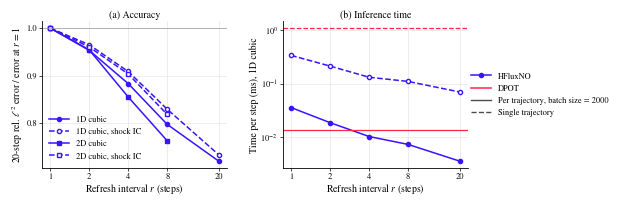

In [21]:
fig

## Table rows

The rows of the error table and of the time table of the appendix, ready to paste, with the error reductions and speed-ups that the text quotes.

In [5]:
def latex_cell(mean: float, std: float, unit: float) -> str:
    """The mean to three significant digits and the std to as many decimals."""
    mean, std = mean / unit, std / unit
    decimals = max(0, 2 - int(np.floor(np.log10(abs(mean)))))
    return f"\\({mean:.{decimals}f} \\pm {std:.{decimals}f}\\)"


# Rows of the error table, in units of 1e-2: r, then l2 and l-infinity in distribution
# and under shock-dominated initial conditions.
UNIT = 1e-2
for family in ("1D cubic", "2D cubic"):
    sets = [s for s in (family, f"{family}, shock IC")]
    intervals = sorted(
        set().union(*(errors[s]["l2_rollout"] for s in sets if s in errors))
    )
    print(f"% {family}")
    for r in intervals:
        cells = [
            latex_cell(*errors[s][field][r], UNIT)
            if s in errors and r in errors[s][field]
            else "--"
            for s in sets
            for field in ("l2_rollout", "l_inf_rollout")
        ]
        print(f"      & {r:<2d} & " + " & ".join(cells) + " \\\\")

# Reduction of the 20-step l2 error at each refresh interval, in percent.
print()
for label in ERROR_SETS:
    by_r = errors[label]["l2_rollout"]
    drops = ", ".join(
        f"r={r}: {100 * (1 - by_r[r][0] / by_r[1][0]):.0f}%"
        for r in sorted(by_r)
        if r != 1
    )
    print(f"{label}: {drops}")

# Rows of the time table, and the speed-up over no reuse.
print()
for mode, name in (
    ("batched", "Time, batched (ms / trajectory)"),
    ("single", "Time, single (ms)"),
):
    times = step_times[mode]
    print(
        f"    {name} & "
        + " & ".join(f"{t:.3g}" for t in times.values())
        + f" & {dpot_times.get(mode, float('nan')):.3g} \\\\"
    )
    if 1 in times:
        print(
            "    % speed-up: "
            + ", ".join(
                f"r={r}: {times[1] / t:.1f}x" for r, t in times.items() if r != 1
            )
        )

% 1D cubic
      & 1  & \(5.22 \pm 0.21\) & \(36.8 \pm 1.6\) & \(6.70 \pm 0.17\) & \(43.5 \pm 0.9\) \\
      & 2  & \(4.98 \pm 0.20\) & \(35.1 \pm 1.5\) & \(6.46 \pm 0.16\) & \(42.0 \pm 0.9\) \\
      & 4  & \(4.61 \pm 0.17\) & \(32.4 \pm 1.3\) & \(6.09 \pm 0.16\) & \(39.4 \pm 0.8\) \\
      & 8  & \(4.16 \pm 0.13\) & \(28.9 \pm 1.0\) & \(5.56 \pm 0.15\) & \(35.7 \pm 0.8\) \\
      & 20 & \(3.76 \pm 0.08\) & \(24.5 \pm 0.5\) & \(4.91 \pm 0.15\) & \(29.5 \pm 0.7\) \\
% 2D cubic
      & 1  & \(1.31 \pm 0.07\) & \(6.38 \pm 0.34\) & \(17.6 \pm 2.4\) & \(56.5 \pm 7.5\) \\
      & 2  & \(1.25 \pm 0.06\) & \(6.03 \pm 0.29\) & \(16.9 \pm 2.4\) & \(55.3 \pm 7.7\) \\
      & 4  & \(1.12 \pm 0.04\) & \(5.45 \pm 0.21\) & \(15.9 \pm 2.2\) & \(52.7 \pm 7.3\) \\
      & 8  & \(0.999 \pm 0.029\) & \(4.87 \pm 0.16\) & \(14.4 \pm 2.0\) & \(48.6 \pm 6.7\) \\

1D cubic: r=2: 5%, r=4: 12%, r=8: 20%, r=20: 28%
1D cubic, shock IC: r=2: 4%, r=4: 9%, r=8: 17%, r=20: 27%
2D cubic: r=2: 5%, r=4: 15%, r=8: 24%
2D